<a href="https://colab.research.google.com/github/bu11ymaguire/SKT_FLY_AI_8/blob/main/12_26_vol3_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#NN 다중분류 - MNIST

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

In [ ]:
import random
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
np.set_printoptions(precision=4,linewidth=200)
keras.utils.set_random_seed(SEED)

#데이터 준비

In [ ]:
(x_train,y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train.shape, y_train.shape, x_test.shape, y_test.shape

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

## EDA

In [ ]:
pd.Series(y_train).value_counts().sort_index()

,count
0,5923
1,6742
2,5958
3,6131
4,5842
5,5421
6,5918
7,6265
8,5851
9,5949


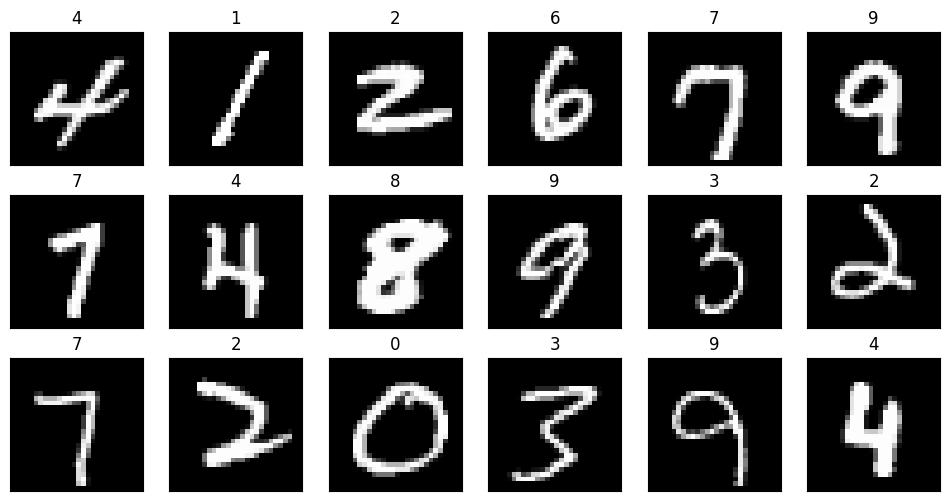

In [ ]:
samples = np.random.randint(len(x_train), size=18)

plt.figure(figsize = (12, 6))
for i, idx in enumerate(samples):
    plt.subplot(3, 6, i+1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(x_train[idx], cmap = 'gray')
    plt.title(y_train[idx].item())
plt.show()

## 데이터 분리


In [ ]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.2,shuffle=True,random_state=SEED)

In [ ]:
x_train.shape, x_val.shape, y_train.shape, y_val.shape

((48000, 28, 28), (12000, 28, 28), (48000,), (12000,))

## 스케일링(Normalization)

In [ ]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  17,  47,  47,  47,  47,  47,  47,  28,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,  63,   0,   0,   0,  62, 138, 197, 197, 197, 217, 253, 253, 253, 253, 253, 253, 230,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0, 151, 170,   0,  56, 232, 250, 253, 231, 217, 217, 217, 217, 217, 217, 217, 128, 179, 132,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0, 104, 251, 170,  20, 233, 253, 199,  84,  26,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   5, 203, 253, 160,   3,  20,  20,   7,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  77, 253, 228,  21,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 150, 253, 249, 223, 223, 193,  71,   6,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 126, 253, 253, 253, 253, 253, 253, 196, 121,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   8, 202, 191, 144, 144, 217, 251, 253, 253, 170,   4,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  53, 236, 253, 253, 215,   3,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  34, 180, 253, 253, 128,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   2, 140, 253, 236,  36,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  37,   0,   0,   0,   0,   0,   0,   0,   0,  13, 215, 253,  62,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 246,  53,   0,   0,   0,   0,   0,   0,   0,   0, 105, 253,  62,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 254,  57,   0,   0,   0,   0,   0,   0,   0,   0,  99, 253,  62,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 255,  65,   0,   0,   0,   0,   0,   0,   0,  35, 217, 253,  62,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 227, 223, 115,  18,   0,   0,   5,  68, 113, 222, 253, 242,  46,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  41, 224, 253, 227, 218, 218, 220, 253, 253, 253, 249,  76,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  35, 150, 215, 253, 253, 253, 253, 205, 175,  57,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  16,  46,  46,  46,  46,   8,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0

In [ ]:
x_train = x_train / 255.0 #min-max Scaling
x_val = x_val / 255.0

In [ ]:
x_train[0]

array([[0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    , 0.    ,
        0.    , 0.    , 0.    , 0.    , 0.    ],
       [0.    , 0.    , 0.    , 0.  

## 인코딩

In [ ]:
from keras.utils import to_categorical

y_train_e = to_categorical(y_train , num_classes = 10)
y_val_e = to_categorical(y_val , num_classes = 10)

## 최종 학습 데이터

In [ ]:
type(x_train), type(y_train_e)

(numpy.ndarray, numpy.ndarray)

# 학습
## 모델

In [ ]:
x_train = x_train.reshape(-1, 28*28)
x_val = x_val.reshape(-1, 28*28)

In [ ]:
x_train.shape

(48000, 784)

In [ ]:
import keras
from keras import layers

model = keras.Sequential([
    keras.Input(shape=(784,)),
    layers.Dense(units=64, activation="relu"),
    layers.Dense(units=32, activation="relu"),
    layers.Dense(units=10, activation="softmax")
])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,650 (205.66 KB)

 Trainable params: 52,650 (205.66 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    loss= "categorical_crossentropy",
    optimizer= "adam",
    metrics=["acc"]
)

## 콜백함수

In [ ]:
es = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    mode = "min",
    patience = 20
)

In [ ]:
EPOCHS = 100
BATCH_SIZE = 64

history = model.fit(x_train, y_train_e,
          epochs=EPOCHS,
          validation_data=(x_val, y_val_e),
          callbacks=[es],
          batch_size= BATCH_SIZE,
          verbose= 1
)

Epoch 1/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - acc: 0.7948 - loss: 0.6919 - val_acc: 0.9399 - val_loss: 0.2114
Epoch 2/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.9437 - loss: 0.1967 - val_acc: 0.9542 - val_loss: 0.1558
Epoch 3/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.9610 - loss: 0.1368 - val_acc: 0.9619 - val_loss: 0.1315
Epoch 4/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - acc: 0.9691 - loss: 0.1061 - val_acc: 0.9657 - val_loss: 0.1190
Epoch 5/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - acc: 0.9754 - loss: 0.0859 - val_acc: 0.9681 - val_loss: 0.1121
Epoch 6/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - acc: 0.9796 - loss: 0.0706 - val_acc: 0.9685 - val_loss: 0.1105
Epoch 7/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - acc: 0.9827 - loss: 0.0597 - val_acc: 0.9691 - val_loss: 0.1101
Epoch 8/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - acc: 0.9855 - loss: 0.0509 - val_acc: 0.9702 - val_loss: 0.1108
Epoch 9/100
750/750 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/

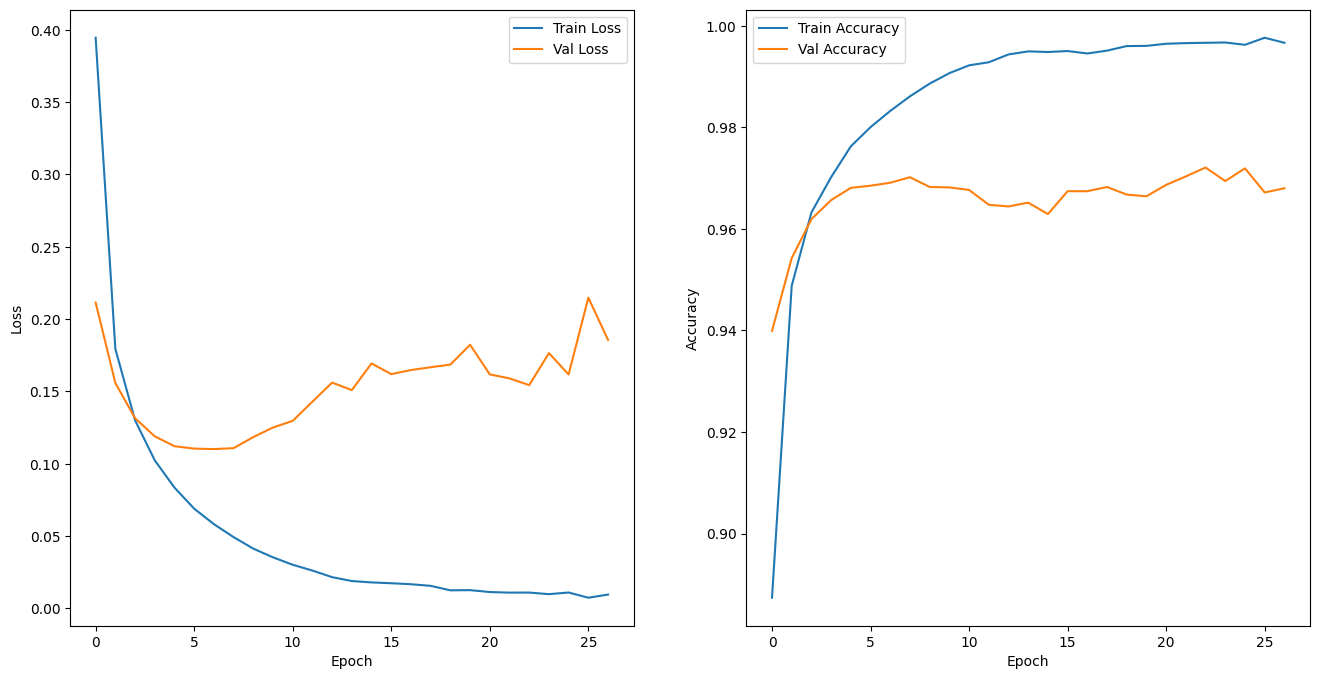

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

def plot_history(history):
  hist = pd.DataFrame(history.history)
  hist['epoch'] = history.epoch

  plt.figure(figsize=(16,8))

  plt.subplot(1,2,1)
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.plot(hist['epoch'], hist['loss'],label='Train Loss')
  plt.plot(hist['epoch'], hist['val_loss'], label = 'Val Loss')
  plt.legend()

  plt.subplot(1,2,2)
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.plot(hist['epoch'], hist['acc'], label='Train Accuracy')
  plt.plot(hist['epoch'], hist['val_acc'], label = 'Val Accuracy')

  plt.legend()
  plt.show()

plot_history(history)

In [ ]:
x_test = x_test / 255.0
y_test_e = to_categorical(y_test , num_classes = 10)
x_test = x_test.reshape(-1, 28*28)

# 테스트

In [ ]:
y_pred = model.predict(x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


In [ ]:
y_pred = np.argmax(y_pred, axis = 1)

In [ ]:
y_pred[:10], y_test[:10]

(array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9]),
 array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9], dtype=uint8))

정확도 0.9683
정밀도 0.9680
재현율 0.9681
f1 0.9680


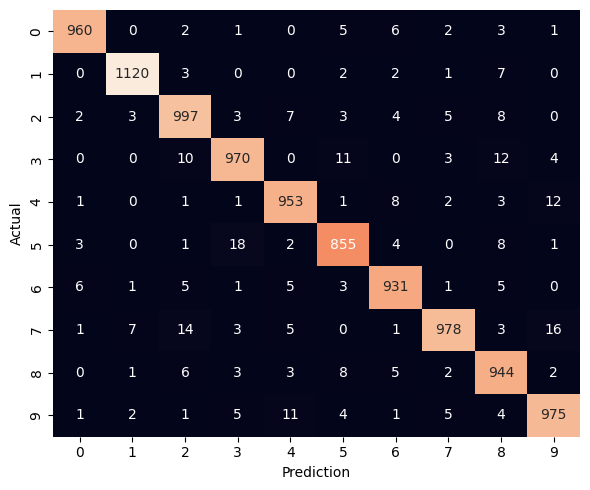

In [ ]:
from sklearn.metrics import accuracy_score,precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns # Ensure seaborn is imported for heatmap
import numpy as np # Import numpy for argmax

def print_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    # Specify average for multiclass classification, 'macro' is a common choice.
    pre = precision_score(y_true, y_pred, average='macro')
    recall = recall_score(y_true, y_pred, average='macro')
    f1 = f1_score(y_true, y_pred, average='macro')

    print(f"정확도 {acc:.4f}")
    print(f"정밀도 {pre:.4f}")
    print(f"재현율 {recall:.4f}")
    print(f"f1 {f1:.4f}")

    cfm = confusion_matrix(y_true,y_pred)

    plt.figure(figsize=(6, 5)) # Optional: Adjust figure size for better visualization
    s = sns.heatmap( cfm,annot=True, fmt='d',cbar=False )
    s.set( xlabel='Prediction',ylabel='Actual')
    plt.tight_layout() # Optional: Adjust layout to prevent labels from overlapping
    plt.show()

# Convert predicted probabilities to class labels
y_pred_classes = np.argmax(y_pred, axis=1)

# Now call the print_metrics function with original integer labels for y_test
print_metrics(y_test, y_pred_classes)
